# Tagging EDA: why regex first, a classifier for the tail, and a hand-written gold set

**The question.** How should we label what each card effect *does*, so that (a) the game engine can run it and (b) the PCA gets useful features?

**The answer this notebook builds evidence for:**

1. Matching exact wordings cannot work, because most effects are worded in a way that appears only once (section 2).
2. A handful of regex patterns, one per building-block verb, labels most effects cheaply (section 3).
3. The patterns agree with the hand-written gold set, but the patterns were tuned on that set, so the number is optimistic (section 4).
4. The effects the patterns miss are mostly worded like the ones they catch, so a classifier is a reasonable tool for them (sections 5 and 6).
5. Some misses are genuine gaps in the vocabulary. That is why there is an `unknown` label and a rule for extending the vocabulary (section 7).

**Data.** `moves.parquet`: 2,265 moves, 1,671 of which have effect text. **Gold set:** the 54 effects of the two chosen decks, written by hand as data in `src/tcg_bot/effects_data.py`.

**How the tests fit in.** The tests in `tests/` are the safety net under this analysis. Each section below ends with a "Guarded by" note, and section 9 runs the whole suite from inside the notebook so you can see it pass.

| Section | What it establishes | Tests that protect it |
|---|---|---|
| 1. What the texts look like | the data we are tagging | `test_plain_damage_attacks_are_exactly_the_moves_without_text` |
| 2. Exact templates | why wording-matching fails | none (pure measurement) |
| 3. Regex patterns | what the cheap layer covers | `test_ability_usage_tags_match_the_card_text` |
| 4. Gold set accuracy | how good the patterns are | `test_one_effect_per_in_scope_move`, `test_numbers_in_the_text...`, `test_key_words_in_the_text...` |
| 5 and 6. Tail and classifier | whether a classifier can help | none yet (needs hand labels outside the two decks) |
| 7. Vocabulary gaps | where the vocabulary must grow | `test_schema_rejects_mistakes`, `test_only_known_effects_are_not_ok` |
| 8. The two decks | the tags the engine will actually use | `test_every_effect_builds`, the deck tests |

**Run order.** Top to bottom, with the project kernel (`tcg_bot`), so that `from tcg_bot...` works.

In [26]:
import re, dataclasses, collections, subprocess, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path("/Users/tam_pr/tcg_bot")
PROC = ROOT / "data" / "processed"
moves = pd.read_parquet(PROC / "moves.parquet")
cards = pd.read_parquet(PROC / "cards.parquet")
deck_cards = pd.read_parquet(PROC / "deck_cards.parquet")

fx = moves[moves["effect_text"].notna()].copy()          # every move that has effect text
print(len(moves), "moves |", len(fx), "have effect text |", fx["effect_text"].nunique(), "distinct texts")

2265 moves | 1671 have effect text | 1133 distinct texts


## 1. What do the effect texts look like?

Before choosing a tagging method we look at the thing being tagged. Three plain questions:

- **How many moves have text at all, and of which kind?** Attacks with no text are plain damage: there is nothing to tag.
- **How long and how varied are the texts?** Short, repetitive text suggests rules can work. Long, varied text suggests they cannot.
- **Which words dominate?** The most common words and word pairs hint at the verbs the vocabulary needs.

**What to look for.** In the first chart, abilities and Trainer effects always have text, while a large share of attacks do not. In the length plots, most effects are one or two short sentences.

**Guarded by:** `test_plain_damage_attacks_are_exactly_the_moves_without_text` checks that, for the two decks, the nine attacks without text are exactly the nine plain-damage attacks in the effect data.

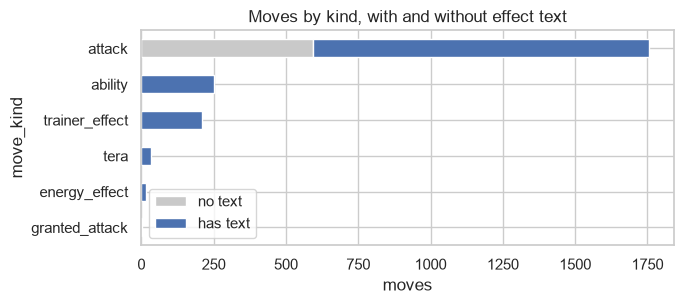

,no text,has text,share_with_text
move_kind,,,
ability,0,251,1.00
attack,594,1160,0.66
energy_effect,0,17,1.00
granted_attack,0,1,1.00
tera,0,32,1.00
trainer_effect,0,210,1.00


In [27]:
# 1a. Which moves have text? (a plain-damage attack has none)
by_kind = moves.assign(has_text=moves["effect_text"].notna()).groupby(["move_kind", "has_text"]).size().unstack(fill_value=0)
by_kind.columns = ["no text", "has text"]
ax = by_kind.sort_values("has text").plot.barh(stacked=True, figsize=(7, 3.2), color=["#c9c9c9", "#4c72b0"])
ax.set_xlabel("moves"); ax.set_title("Moves by kind, with and without effect text")
plt.tight_layout(); plt.show()
by_kind.assign(share_with_text=(by_kind["has text"] / by_kind.sum(axis=1)).round(2))

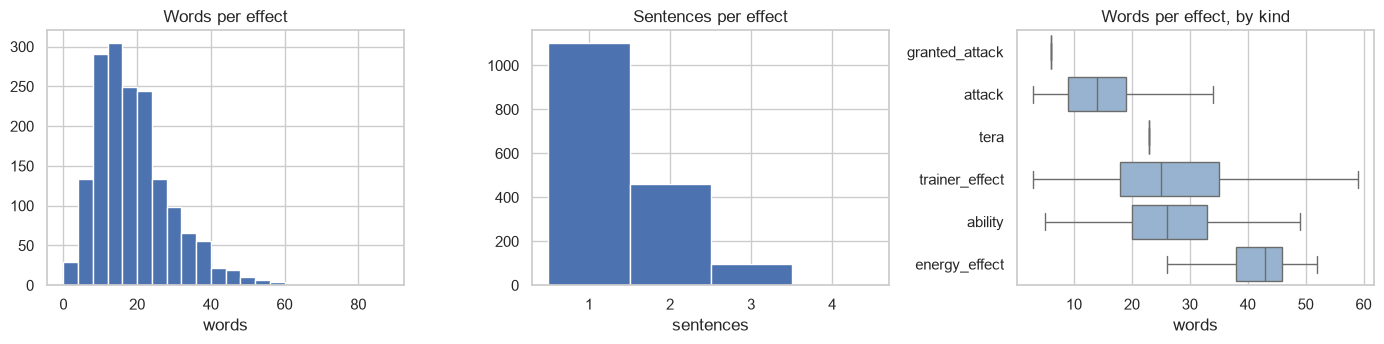

      words  sentences  chars
mean   18.7        1.4  103.3
50%    17.0        1.0   93.0
max    93.0        4.0  499.0


In [28]:
# 1b. How long are the texts?
fx["chars"] = fx["effect_text"].str.len()
fx["words"] = fx["effect_text"].str.split().str.len()
fx["sentences"] = fx["effect_text"].map(lambda t: len([x for x in re.split(r"(?<=[.!?])\s+(?=[A-Z])", re.sub(r"\s+", " ", t)) if x.strip()]))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(fx["words"], bins=range(0, 90, 4), color="#4c72b0"); axes[0].set_title("Words per effect"); axes[0].set_xlabel("words")
axes[1].hist(fx["sentences"], bins=np.arange(0.5, fx["sentences"].max() + 1.5), color="#4c72b0"); axes[1].set_title("Sentences per effect"); axes[1].set_xlabel("sentences")
order = fx.groupby("move_kind")["words"].median().sort_values().index
sns.boxplot(data=fx, y="move_kind", x="words", order=order, ax=axes[2], color="#8fb3d9", showfliers=False)
axes[2].set_title("Words per effect, by kind"); axes[2].set_xlabel("words"); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()
print(fx[["words", "sentences", "chars"]].describe().round(1).loc[["mean", "50%", "max"]])

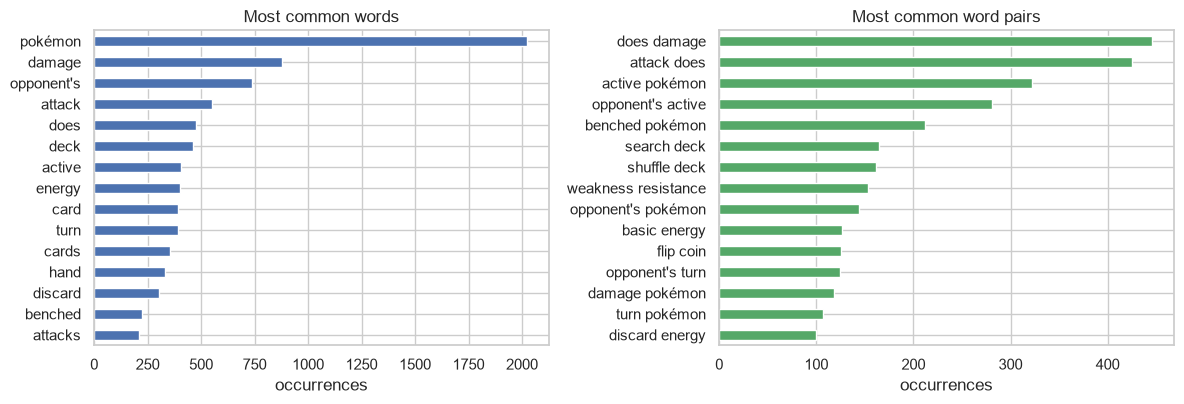

In [29]:
# 1c. Which words and word pairs dominate? (stop words removed; numbers and names masked later, here only lowercased)
from sklearn.feature_extraction.text import CountVectorizer
def top_terms(ngram, n=15):
    cv = CountVectorizer(ngram_range=ngram, stop_words="english", token_pattern=r"[a-zA-Zé']{3,}")
    m = cv.fit_transform(fx["effect_text"].str.lower())
    s = pd.Series(np.asarray(m.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    return s.sort_values(ascending=False).head(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
top_terms((1, 1)).sort_values().plot.barh(ax=axes[0], color="#4c72b0"); axes[0].set_title("Most common words"); axes[0].set_xlabel("occurrences")
top_terms((2, 2)).sort_values().plot.barh(ax=axes[1], color="#55a868"); axes[1].set_title("Most common word pairs"); axes[1].set_xlabel("occurrences")
plt.tight_layout(); plt.show()

## 2. Can we tag by exact template?

The simplest idea: write one rule per distinct wording. To see if that is feasible we **mask** the parts that vary (numbers, energy symbols, Pokémon names, status names, heads or tails) and count how often each masked wording, or *template*, repeats.

**What to look for.**
- If most templates repeat many times, one rule per template is cheap.
- If most appear **once**, the rules would never stop growing. That is the "long tail".

The left chart shows how many templates are needed to cover a given share of all sentences. It rises steeply for the common templates, then turns into a **straight line**: past that bend, every extra template is a one-off that adds the same tiny amount. The right chart is the same story as counts: most templates appear exactly once.

**Reading the result.** Roughly 8 in 10 whole-text templates appear once, and covering 80% of sentences takes several hundred templates. So exact matching cannot be the method. We need rules that generalise across wordings, which is what the next two sections test.

**Guarded by:** nothing, since this is a pure measurement. Its role is to justify the design, not to check code.

whole-text templates: 957 for 1671 effects | appear once: 785 (82%)
the 50 most common templates cover 35% of effects
sentence templates: 1089 from 2351 sentences | appear once: 850
templates needed for 50% / 80% / 90% of sentences: [95, 619, 854]


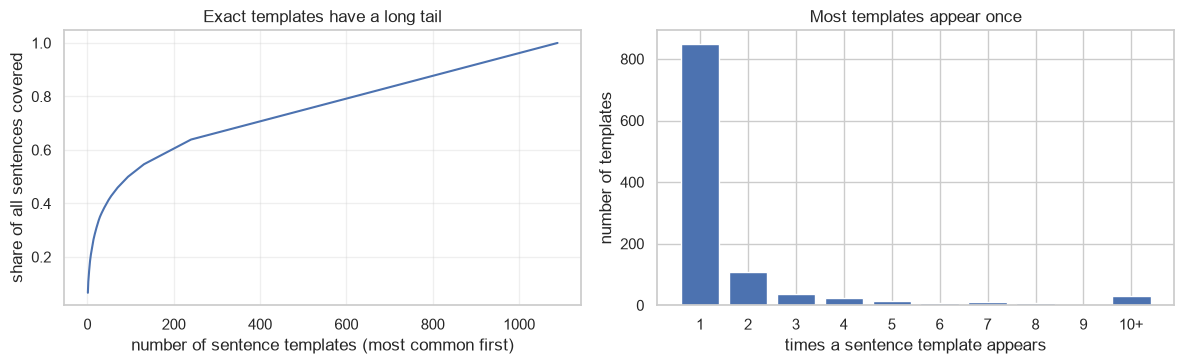

In [30]:
pokemon_names = sorted({n for n in cards.loc[cards["family"] == "pokemon", "card_name"].dropna().unique()
                        if re.fullmatch(r"[A-Z][a-zé'’\-]{4,}", n)}, key=len, reverse=True)
NAME = re.compile(r"\b(?:" + "|".join(map(re.escape, pokemon_names)) + r")\b")

def mask(s):
    s = NAME.sub("<NAME>", s)                                      # card names
    s = re.sub(r"\{[A-Za-z ]+\}", "<E>", s)                        # energy symbols
    s = re.sub(r"\b\d+\b", "<N>", s)                               # numbers
    s = re.sub(r"\b(Asleep|Burned|Confused|Paralyzed|Poisoned)\b", "<STATUS>", s)
    return re.sub(r"\b(heads|tails)\b", "<HT>", s)

def sentences(t):
    return [x.strip() for x in re.split(r"(?<=[.!?])\s+(?=[A-Z])", re.sub(r"\s+", " ", t)) if x.strip()]

fx["masked"] = fx["effect_text"].map(mask)
whole = fx["masked"].value_counts()
print(f"whole-text templates: {len(whole)} for {len(fx)} effects | appear once: {(whole == 1).sum()} ({(whole == 1).mean():.0%})")
print(f"the 50 most common templates cover {whole.head(50).sum() / len(fx):.0%} of effects")

sent = collections.Counter(mask(s) for t in fx["effect_text"] for s in sentences(t))
counts = np.array([v for _, v in sent.most_common()]); cum = np.cumsum(counts) / counts.sum()
print(f"sentence templates: {len(sent)} from {counts.sum()} sentences | appear once: {(counts == 1).sum()}")
print("templates needed for 50% / 80% / 90% of sentences:", [int(np.searchsorted(cum, q) + 1) for q in (.5, .8, .9)])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(range(1, len(cum) + 1), cum); axes[0].set_xlabel("number of sentence templates (most common first)")
axes[0].set_ylabel("share of all sentences covered"); axes[0].set_title("Exact templates have a long tail"); axes[0].grid(alpha=.3)
rep = pd.Series(counts).clip(upper=10).value_counts().sort_index()
axes[1].bar(rep.index.astype(str).str.replace("10", "10+"), rep.values, color="#4c72b0")
axes[1].set_xlabel("times a sentence template appears"); axes[1].set_ylabel("number of templates"); axes[1].set_title("Most templates appear once")
plt.tight_layout(); plt.show()

## 3. Regex first: one pattern per building-block verb

The effect vocabulary (`src/tcg_bot/effects.py`) is made of a few verbs: search the deck, draw, switch, discard, heal, apply a status, and so on. We write **one regular expression per verb** and ask how much of the pool they label.

**Two things to read off the charts.**
- **Coverage curve (left).** Patterns are added most frequent first. A steep rise then a plateau means the cheap layer catches the common cases quickly and then runs out. The plateau is the share left for another method.
- **Effects per verb (right).** The verb counts are very uneven. Rare verbs (here `recover_discard` and `shuffle_hand`) have too few examples for a classifier, so they must be handled by rules or hand labels.

**Why these verbs.** They are the same verbs as the effect schema, so a label here maps directly onto a block the engine will run.

**Guarded by:** `test_ability_usage_tags_match_the_card_text` checks the separate usage-limit tags (once per Pokémon, per name, first turn only) against the ability text. That is the same kind of text-to-tag agreement, measured here on the verbs.

17 patterns label 1368 of 1671 effects (82%)
labels per effect: mean 1.05, max 3
no label at all: 303 (18%) | by kind: {'attack': 148, 'ability': 101, 'trainer_effect': 46, 'energy_effect': 8}
labels with fewer than 15 examples: ['recover_discard', 'shuffle_hand']


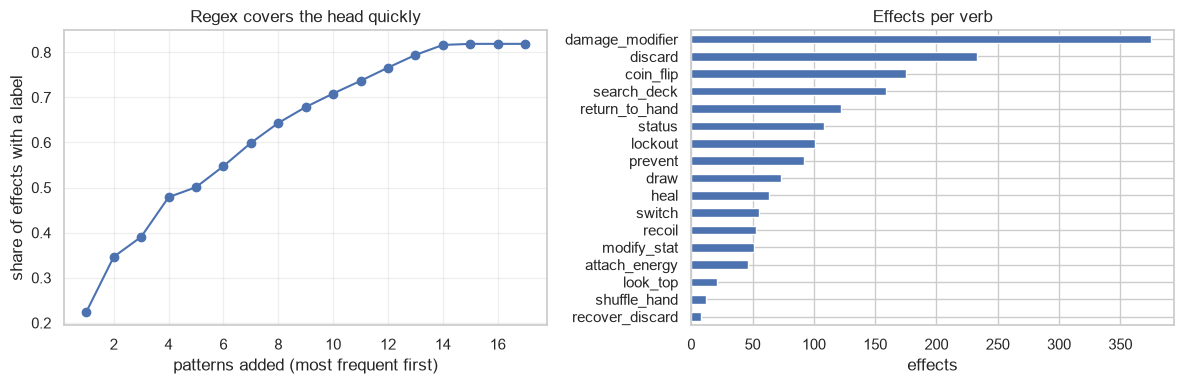

In [31]:
VERBS = {
    "search_deck":     r"[Ss]earch your deck",
    "look_top":        r"[Ll]ook at the top",
    "recover_discard": r"[Pp]ut .{0,60}from your discard pile into your hand",
    "attach_energy":   r"[Aa]ttach .{0,80}Energy",
    "discard":         r"\b[Dd]iscards?\b(?! pile)",
    "shuffle_hand":    r"shuffles? (?:their|your) hand|[Ss]huffle your hand",
    "return_to_hand":  r"into your hand",
    "draw":            r"[Dd]raws? (?:a|an|\d+|up to \d+|that many) cards?|draws? \d+",
    "switch":          r"[Ss]witch",
    "heal":            r"[Hh]eal",
    "status":          r"is now (?:Asleep|Burned|Confused|Paralyzed|Poisoned)",
    "recoil":          r"damage to itself",
    "lockout":         r"can't use (?!more than)|can't attack|can't retreat",
    "prevent":         r"[Pp]revent",
    "modify_stat":     r"attacks used by .{0,60}do \d+ more damage|[-+]\d+ HP|Retreat Cost.{0,80}less|takes \d+ less damage",
    "coin_flip":       r"[Ff]lips? (?:a|\d+) coins?",
    "damage_modifier": r"this attack does .{0,40}more damage|damage for each|isn't affected|does nothing|This attack's damage",
}
labels = list(VERBS)
for k, p in VERBS.items():
    fx[k] = fx["effect_text"].str.contains(p, regex=True).astype(bool)
fx["n_labels"] = fx[labels].sum(axis=1)

print(f"{len(VERBS)} patterns label {(fx['n_labels'] > 0).sum()} of {len(fx)} effects ({(fx['n_labels'] > 0).mean():.0%})")
print(f"labels per effect: mean {fx['n_labels'].mean():.2f}, max {fx['n_labels'].max()}")
order = fx[labels].sum().sort_values(ascending=False).index
seen, curve = pd.Series(False, index=fx.index), []
for k in order:
    seen |= fx[k]; curve.append(seen.mean())
unlabelled = fx[fx["n_labels"] == 0]
print(f"no label at all: {len(unlabelled)} ({len(unlabelled) / len(fx):.0%}) | by kind: {unlabelled['move_kind'].value_counts().to_dict()}")
print("labels with fewer than 15 examples:", [k for k in labels if fx[k].sum() < 15])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(curve) + 1), curve, marker="o"); axes[0].set_xlabel("patterns added (most frequent first)")
axes[0].set_ylabel("share of effects with a label"); axes[0].set_title("Regex covers the head quickly"); axes[0].grid(alpha=.3)
fx[labels].sum().sort_values().plot.barh(ax=axes[1], color="#4c72b0"); axes[1].set_title("Effects per verb"); axes[1].set_xlabel("effects")
plt.tight_layout(); plt.show()

### 3b. Standard views of the labels

Four more views of the same labels, each answering a different question:

- **Labels per effect (top left).** Is tagging multi-label? Mostly one verb per effect, sometimes two or three.
- **Which verbs occur together (top right).** The heatmap counts effects that carry both verbs. The brightest off-diagonal cells are real wording patterns: `coin_flip` with `damage_modifier` ("Flip a coin. If tails, this attack does nothing", 87 effects) and `search_deck` with `return_to_hand` (81 effects). The second pair is not two actions but **one** action counted twice, since a search ends with "put it into your hand". That is why `return_to_hand` should become a *parameter* of the card-moving step (destination = hand), not a verb of its own.
- **Labelled share by kind (bottom left).** Where does the regex layer fall short? Abilities and Energy effects are the hardest.
- **Verb by kind (bottom right).** Which kinds of card use which verbs. This is where a classifier would need separate examples per kind.

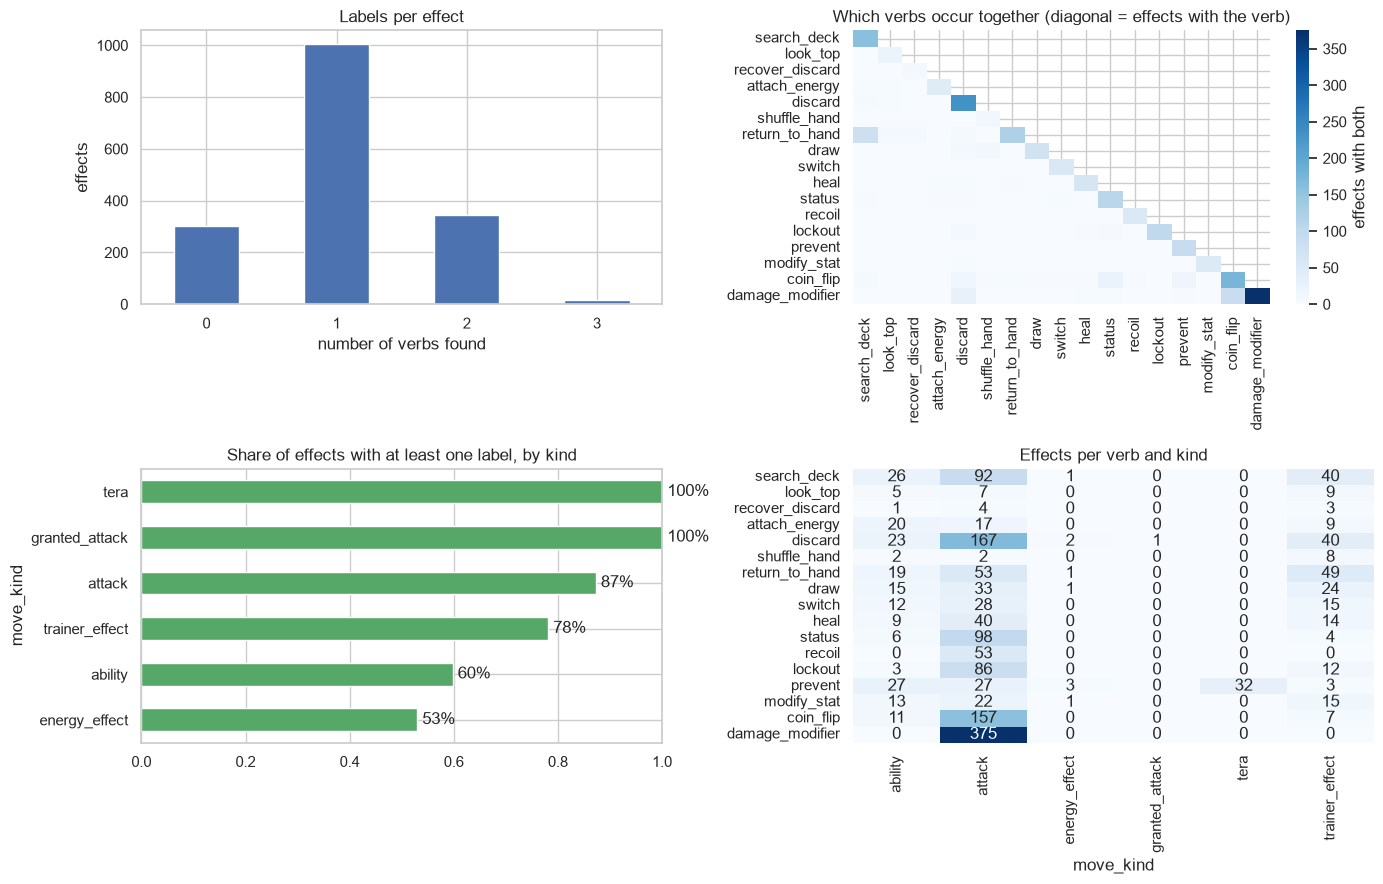

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fx["n_labels"].value_counts().sort_index().plot.bar(ax=axes[0, 0], color="#4c72b0", rot=0)
axes[0, 0].set_title("Labels per effect"); axes[0, 0].set_xlabel("number of verbs found"); axes[0, 0].set_ylabel("effects")

co = fx[labels].astype(int).T @ fx[labels].astype(int)
mask_upper = np.triu(np.ones_like(co, dtype=bool))
sns.heatmap(co.where(~mask_upper | np.eye(len(co), dtype=bool)), ax=axes[0, 1], cmap="Blues", annot=False, cbar_kws={"label": "effects with both"})
axes[0, 1].set_title("Which verbs occur together (diagonal = effects with the verb)")

share = fx.assign(labelled=fx["n_labels"] > 0).groupby("move_kind")["labelled"].mean().sort_values()
share.plot.barh(ax=axes[1, 0], color="#55a868"); axes[1, 0].set_xlim(0, 1); axes[1, 0].set_title("Share of effects with at least one label, by kind")
for i, (k, v) in enumerate(share.items()): axes[1, 0].text(v + .01, i, f"{v:.0%}", va="center")

vk = fx.groupby("move_kind")[labels].sum().T
sns.heatmap(vk, ax=axes[1, 1], cmap="Blues", annot=True, fmt="d", cbar=False)
axes[1, 1].set_title("Effects per verb and kind")
plt.tight_layout(); plt.show()

## 4. How accurate are the patterns? The hand-written gold set

Labels are only useful if they are right. The only effects whose meaning we wrote out by hand are the **54 effects of the two decks** (`src/tcg_bot/effects_data.py`). Each hand-written effect already says which verbs it uses, so we can derive its "gold" labels and compare them with what the regex patterns predict.

**The three counts**, per verb:
- **TP (true positive):** the pattern says the verb is there, and the hand-written effect agrees.
- **FP (false positive):** the pattern says the verb is there, but the hand-written effect does not use it (a false alarm).
- **FN (false negative):** the hand-written effect uses the verb, but the pattern missed it.

Precision is `TP / (TP + FP)`: when the pattern fires, how often is it right? Recall is `TP / (TP + FN)`: of the real cases, how many did it find? F1 combines the two.

**An honest caveat.** I refined the patterns after seeing which of these 54 effects they got wrong, so the final result is optimistic. The comparison in 4b shows the first draft next to the refined patterns, so the failure modes are visible.

**Guarded by:** the gold set is only trustworthy if it is complete and consistent with the cards, and these tests check exactly that:
- `test_one_effect_per_in_scope_move`: every in-scope move has one hand-written effect.
- `test_every_effect_builds`: each uses only the allowed vocabulary.
- `test_numbers_in_the_text_match_the_numbers_in_the_data` and `test_key_words_in_the_text_match_the_parameters`: the numbers and key words in each text agree with what was written.

In [33]:
from tcg_bot.effects import build, MoveCards, Draw, SwitchActive, Heal, ApplyStatus, DamageSelf, Lockout, Prevent, ModifyStat, CoinFlip
from tcg_bot.effects_data import EFFECTS

def walk(x):
    if dataclasses.is_dataclass(x):
        yield x
        for f in dataclasses.fields(x):
            yield from walk(getattr(x, f.name))
    elif isinstance(x, (tuple, list)):
        for y in x:
            yield from walk(y)

def gold_labels(effect):
    g = set()
    for n in walk(effect):
        if isinstance(n, MoveCards):
            if n.look_n: g.add("look_top")
            if n.source == "deck": g.add("search_deck")
            if n.source == "discard" and n.destination == "hand": g.add("recover_discard")
            if n.destination == "attached_to_bench": g.add("attach_energy")
            if n.destination == "discard": g.add("discard")
            if n.source == "hand" and n.destination in ("deck_shuffle", "deck_bottom"): g.add("shuffle_hand")
            if n.destination == "hand": g.add("return_to_hand")
        elif isinstance(n, Draw): g.add("draw")
        elif isinstance(n, SwitchActive): g.add("switch")
        elif isinstance(n, Heal): g.add("heal")
        elif isinstance(n, ApplyStatus): g.add("status")
        elif isinstance(n, DamageSelf): g.add("recoil")
        elif isinstance(n, Lockout): g.add("lockout")
        elif isinstance(n, Prevent): g.add("prevent")
        elif isinstance(n, ModifyStat): g.add("modify_stat")
        elif isinstance(n, CoinFlip): g.add("coin_flip")
    if effect.damage is not None or effect.ignore_defender_effects or effect.ignore_weakness_resistance or effect.works_only_if:
        g.add("damage_modifier")
    return g

gold = pd.DataFrame([{"move_id": e["move_id"], **{k: k in gold_labels(build(e)) for k in labels}} for e in EFFECTS]).set_index("move_id")
g = gold.join(fx.set_index("move_id")[labels], rsuffix="_pred", how="inner")      # effects that have text
rows = []
for k in labels:
    tp = int((g[k] & g[k + "_pred"]).sum()); fp = int((~g[k] & g[k + "_pred"]).sum()); fn = int((g[k] & ~g[k + "_pred"]).sum())
    rows.append({"label": k, "tp": tp, "fp": fp, "fn": fn})
res = pd.DataFrame(rows).set_index("label"); tp, fp, fn = res.sum()
print(f"{len(g)} gold effects with text | micro precision {tp / (tp + fp):.2f}, recall {tp / (tp + fn):.2f}, F1 {2 * tp / (2 * tp + fp + fn):.2f}")
print("effects where the patterns and the hand-written data disagree:",
      [i for i in g.index if (g.loc[i, labels].values != g.loc[i, [l + "_pred" for l in labels]].values).any()])
print("\nCAUTION: these 54 effects were also used to refine the patterns, so this is an optimistic number.")
res[(res.sum(axis=1)) > 0]

45 gold effects with text | micro precision 1.00, recall 1.00, F1 1.00
effects where the patterns and the hand-written data disagree: []

CAUTION: these 54 effects were also used to refine the patterns, so this is an optimistic number.


,tp,fp,fn
label,,,
search_deck,8,0,0
look_top,1,0,0
recover_discard,1,0,0
attach_energy,1,0,0
discard,4,0,0
shuffle_hand,5,0,0
return_to_hand,12,0,0
draw,8,0,0
switch,5,0,0


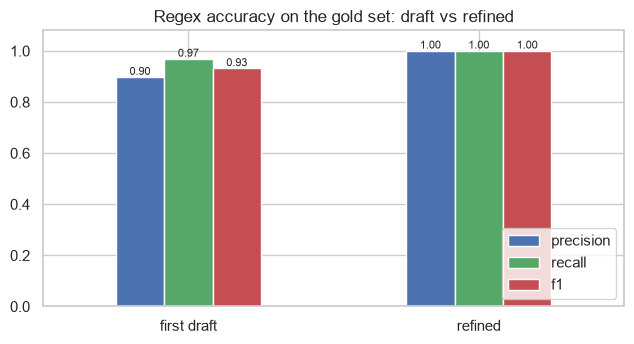

first-draft errors (tp, fp, fn): {'discard': (4, 2, 0), 'lockout': (2, 3, 0), 'modify_stat': (2, 1, 1), 'coin_flip': (1, 0, 1), 'damage_modifier': (5, 1, 0)}


In [34]:
NAIVE = dict(VERBS)
NAIVE.update({
    "discard":         r"[Dd]iscard",
    "lockout":         r"can't use|can't attack|can't retreat",
    "modify_stat":     r"(?:less|more) damage|[-+]\d+ HP|Retreat Cost.{0,40}less|\d+ more damage|do \d+ more",
    "coin_flip":       r"[Ff]lip (?:a|\d+) coins?",
    "damage_modifier": r"damage for each|more damage|isn't affected|does nothing|Weakness and Resistance",
})
texts = fx.set_index("move_id").loc[g.index, "effect_text"]

def score(patterns):
    tp = fp = fn = 0; per = {}
    for k in labels:
        pred = texts.str.contains(patterns[k], regex=True).astype(bool); real = g[k].astype(bool)
        a, b, c = int((real & pred).sum()), int((~real & pred).sum()), int((real & ~pred).sum())
        tp += a; fp += b; fn += c; per[k] = (a, b, c)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {"precision": p, "recall": r, "f1": 2 * p * r / (p + r)}, per

(s_naive, per_naive), (s_final, per_final) = score(NAIVE), score(VERBS)
cmp_ = pd.DataFrame({"first draft": s_naive, "refined": s_final})
ax = cmp_.T.plot.bar(figsize=(6.5, 3.6), rot=0, color=["#4c72b0", "#55a868", "#c44e52"]); ax.set_ylim(0, 1.08)
ax.set_title("Regex accuracy on the gold set: draft vs refined"); ax.legend(loc="lower right")
for p in ax.patches: ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
errs = {k: v for k, v in per_naive.items() if v[1] or v[2]}
print("first-draft errors (tp, fp, fn):", errs)

## 5. Is the unlabelled tail close to the labelled head?

"Head" means the effects whose wording is common and is caught by the patterns. "Tail" means the rest: rare wordings, one-offs, and the effects the patterns miss.

A classifier can only help the tail if the tail is **worded like the head**. To measure that, each effect is turned into a vector of word weights (TF-IDF over words and word pairs). For every unlabelled effect we then find the most similar labelled effect and record the **cosine similarity** (1 means the same words in the same proportions, 0 means no words in common).

**Reading the histogram.** Bars to the right are easy: a labelled effect with nearly the same wording exists. Bars at the far left are the risky ones: nothing similar has a label, so these are the likely candidates for new vocabulary or a hand label.

**The map (5b).** The scatter projects all effects to two dimensions. Some verbs form a clear region (`search_deck` is the clearest), others overlap because many verbs share similar wording. Grey points (unlabelled) sitting inside a coloured region are good classifier candidates. Grey points far from every region are the gaps.

**Guarded by:** nothing yet, because these effects are outside the two decks. This is the main reason the plan includes a hand-labelled holdout.

unlabelled effects: nearest labelled effect has cosine median 0.55 | at least 0.5: 60% | below 0.3: 9%
one-off templates (785): nearest repeated template cosine median 0.52 | at least 0.5: 52%


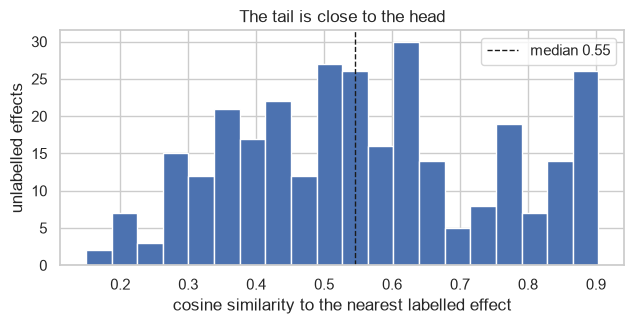

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X = tfidf.fit_transform(fx["masked"])
labelled = (fx["n_labels"] > 0).to_numpy(dtype=bool)
sim = cosine_similarity(X[~labelled], X[labelled]).max(axis=1)
print(f"unlabelled effects: nearest labelled effect has cosine median {np.median(sim):.2f} | at least 0.5: {(sim >= 0.5).mean():.0%} | below 0.3: {(sim < 0.3).mean():.0%}")

once = (fx["masked"].map(whole) == 1).to_numpy(dtype=bool)
sim2 = cosine_similarity(X[once], X[~once]).max(axis=1)
print(f"one-off templates ({once.sum()}): nearest repeated template cosine median {np.median(sim2):.2f} | at least 0.5: {(sim2 >= 0.5).mean():.0%}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(sim, bins=20, color="#4c72b0"); ax.axvline(np.median(sim), color="k", ls="--", lw=1, label=f"median {np.median(sim):.2f}")
ax.set_xlabel("cosine similarity to the nearest labelled effect"); ax.set_ylabel("unlabelled effects")
ax.set_title("The tail is close to the head"); ax.legend(); plt.tight_layout(); plt.show()


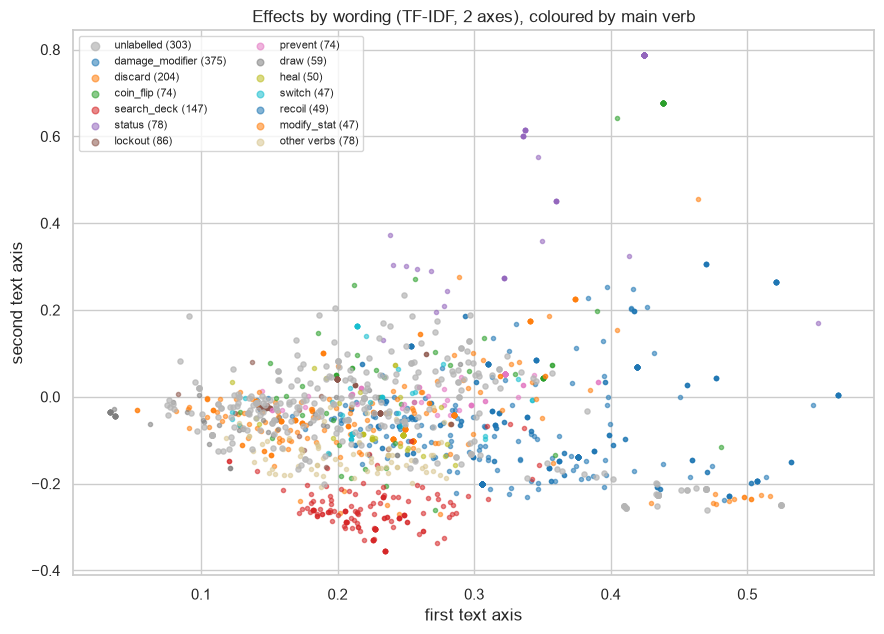

In [36]:
# 5b. A map of all effects: coloured by the most common verb they carry, grey if unlabelled
from sklearn.decomposition import TruncatedSVD
xy = TruncatedSVD(n_components=2, random_state=0).fit_transform(X)
freq_order = list(fx[labels].sum().sort_values(ascending=False).index)
primary = fx[freq_order].astype(bool).idxmax(axis=1).where(fx["n_labels"] > 0, "unlabelled")
top = [k for k in freq_order if (primary == k).sum() >= 40]
palette = dict(zip(top, sns.color_palette("tab10", len(top))))

fig, ax = plt.subplots(figsize=(9, 6.5))
grey = primary == "unlabelled"
ax.scatter(xy[grey, 0], xy[grey, 1], s=14, c="#b5b5b5", label=f"unlabelled ({grey.sum()})", alpha=.7, zorder=3)
for k in top:
    m = (primary == k).to_numpy(); ax.scatter(xy[m, 0], xy[m, 1], s=9, color=palette[k], label=f"{k} ({m.sum()})", alpha=.55)
other = (~grey) & (~primary.isin(top)); ax.scatter(xy[other, 0], xy[other, 1], s=9, c="#d8c690", label=f"other verbs ({other.sum()})", alpha=.55)
ax.set_xlabel("first text axis"); ax.set_ylabel("second text axis"); ax.set_title("Effects by wording (TF-IDF, 2 axes), coloured by main verb")
ax.legend(fontsize=8, markerscale=1.6, loc="best", ncol=2); plt.tight_layout(); plt.show()

## 6. Feasibility of the classifier

If the tail is close to the head, a classifier trained on labelled effects should generalise to unlabelled wording. We test that with TF-IDF features and one logistic regression per verb, scored by 5-fold cross-validation.

**What this does and does not show.** The training labels come from the regex patterns. So an F1 near 1 only shows that a classifier can *reproduce the patterns from the wording*, which is evidence that wording is informative. It does **not** show that the classifier labels the unlabelled 18% correctly. That needs hand labels, which is why the next step in the plan is a hand-labelled holdout.

**Reading the chart.** Verbs with lower F1 (for example `modify_stat`) have the least consistent wording and will need the most attention. Verbs with fewer than 15 examples are left out because there is too little data.

**Guarded by:** nothing yet, for the same reason as section 5.

5-fold macro F1 over 15 labels: 0.96


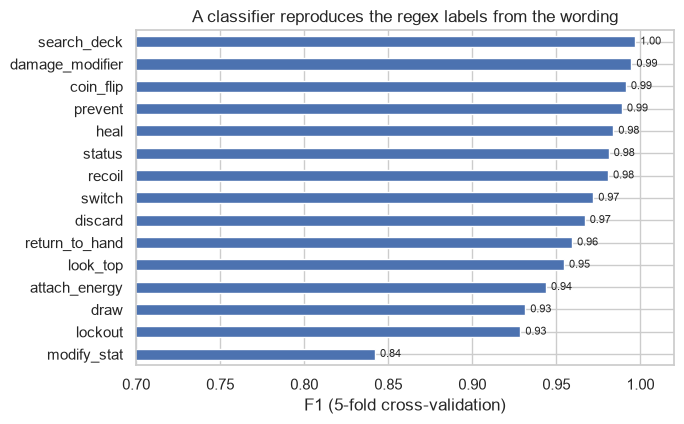

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import f1_score

usable = [k for k in labels if fx[k].sum() >= 15]
Y = fx[usable].to_numpy(dtype=int)
clf = OneVsRestClassifier(LogisticRegression(max_iter=2000, C=10, class_weight="balanced"))
pred = cross_val_predict(clf, X, Y, cv=KFold(5, shuffle=True, random_state=0))
f1s = pd.Series({k: f1_score(Y[:, i], pred[:, i]) for i, k in enumerate(usable)}).sort_values()
print(f"5-fold macro F1 over {len(usable)} labels: {f1_score(Y, pred, average='macro'):.2f}")

fig, ax = plt.subplots(figsize=(7, 4.4))
f1s.plot.barh(ax=ax, color="#4c72b0"); ax.set_xlim(0.7, 1.02); ax.set_xlabel("F1 (5-fold cross-validation)")
ax.set_title("A classifier reproduces the regex labels from the wording")
for i, v in enumerate(f1s): ax.text(v + .003, i, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

## 7. Spot-check and the vocabulary gaps

Numbers can hide problems, so we also read a random sample of effects **from cards outside the two decks** together with the labels the patterns gave them. The sample is fixed by a seed so that it is the same every time.

When I read the 22 shown here, 16 were labelled correctly (this is my own reading; yours may differ slightly). The other 6 were not regex misses but **gaps in the vocabulary**: effects that change an attack's cost, damage a chosen or Benched Pokémon, shuffle cards from play into the deck, or send the opponent's hand to the bottom of their deck.

The chart below counts what the unlabelled effects are about. The tallest bars are the best candidates for new verbs.

**The rule this implies.** Add a verb only when a deck in scope needs it, or when many effects need it. Anything else gets an `unknown` label and a parse status, so it is never silently ignored.

**Guarded by:**
- `test_schema_rejects_mistakes`: the vocabulary cannot be extended by accident, because the builder rejects any unknown block or value.
- `test_only_known_effects_are_not_ok`: only Lucian and Psyduck's Damp may be anything but `ok`.
- `test_damp_has_nothing_to_switch_off_in_these_decks`: a guard that fails if a future deck needs an ability the vocabulary does not cover yet.

In [38]:
rng = np.random.default_rng(7)
outside = fx[~fx["card_id"].isin(deck_cards["card_id"])]
for r in outside.iloc[rng.choice(len(outside), 22, replace=False)].itertuples():
    print(f"[{r.move_kind[:5]}] {r.effect_text[:150]!r}\n      -> {[k for k in labels if getattr(r, k)] or 'NO LABEL'}")

[attac] "During your next turn, this Pokémon can't attack."
      -> ['lockout']
[attac] 'Flip a coin. If tails, this attack does nothing.'
      -> ['coin_flip', 'damage_modifier']
[attac] 'Heal 30 damage from this Pokémon.'
      -> ['heal']
[attac] "Flip a coin. If heads, your opponent's Active Pokémon is now Paralyzed."
      -> ['status', 'coin_flip']
[train] 'You can use this card only if you have more Prize cards remaining than your opponent. Attach up to 2 Basic Energy cards from your discard pile to 1 of'
      -> ['attach_energy']
[attac] "If your opponent's Active Pokémon already has any damage counters on it, this attack does 200 more damage."
      -> ['damage_modifier']
[attac] 'Search your deck for up to 3 Basic Energy cards of different types, reveal them, and put them into your hand. Then, shuffle your deck.'
      -> ['search_deck', 'return_to_hand']
[train] 'Your opponent reveals their hand, and you choose an Energy card you find there and put it on the bottom of the

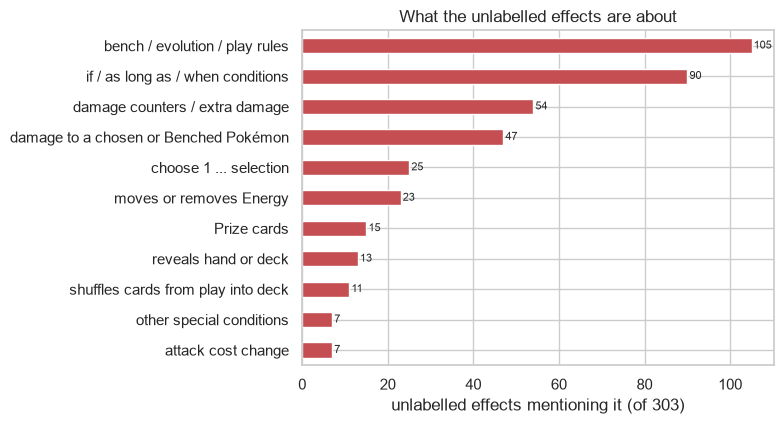

in your two decks, unlabelled: 1 of 303


In [39]:
# What are the unlabelled effects about? (an effect can match more than one theme)
THEMES = {
    "bench / evolution / play rules":      r"[Ee]volv|onto your Bench|on your Bench|Bench",
    "if / as long as / when conditions":   r"\bIf\b|\bAs long as\b|\bWhen\b|\bWhenever\b",
    "damage counters / extra damage":      r"damage counters?",
    "damage to a chosen or Benched Pokémon": r"damage to (?:1|2|\d+) of|damage to each|also does \d+ damage to|Benched Pokémon.{0,40}damage",
    "choose 1 ... selection":              r"[Cc]hoose",
    "moves or removes Energy":             r"[Mm]ove .{0,40}Energy|Energy .{0,20}(?:from|to) 1 of|[Dd]iscard all Energy",
    "Prize cards":                         r"Prize",
    "reveals hand or deck":                r"reveals?",
    "shuffles cards from play into deck":  r"[Ss]huffle .{0,60}(?:into|in) (?:your|their) deck",
    "attack cost change":                  r"cost[s]? .{0,40}less|Energy less",
    "other special conditions":            r"Special Condition|recover from",
}
theme_counts = pd.Series({k: int(unlabelled["effect_text"].str.contains(p, regex=True).sum()) for k, p in THEMES.items()}).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.4))
theme_counts.plot.barh(ax=ax, color="#c44e52"); ax.set_xlabel(f"unlabelled effects mentioning it (of {len(unlabelled)})")
ax.set_title("What the unlabelled effects are about")
for i, v in enumerate(theme_counts): ax.text(v + .5, i, str(v), va="center", fontsize=8)
plt.tight_layout(); plt.show()
print(f"in your two decks, unlabelled: {int(unlabelled['card_id'].isin(deck_cards['card_id']).sum())} of {len(unlabelled)}")

## 8. The two decks: the tags the engine will actually use

Training uses only the two decks, so what matters most is how well **these** cards are covered. The table lists every card in each deck in the order of its `.txt` file, with its card tags (for example `lopunny_pokemon_4 .. 6` for three copies), each move, when it happens (`timing`), any usage limit, the building blocks it is made of, and its status.

**Reading the table.** `-` in `blocks` means a plain-damage attack (nothing to tag). `per_name:Lunar Cycle` is a usage limit that counts across all copies. `status` is `ok` for all but two effects: `complex` for Lucian and `no_effect_in_scope` for Psyduck's Damp.

**Guarded by:**
- `test_one_effect_per_in_scope_move`: the last line of the output, "moves with no effect entry", must be 0.
- `test_every_effect_builds`: every `blocks` entry comes from the allowed vocabulary.
- The deck tests (`test_every_deck_expands_to_60_instances`, `test_tags_are_unique_and_follow_the_pattern`, `test_instance_counts_match_copies`, `test_two_dunsparce_versions_stay_separate`) guard the card tags in the first column.

In [40]:
from tcg_bot.decks import expand_deck

DECKS = ["lopunny", "mega_lucario"]                       # add or remove deck names here
effects = {o.move_id: o for o in (build(e) for e in EFFECTS)}
STEPS = (MoveCards, Draw, SwitchActive, Heal, ApplyStatus, DamageSelf, Lockout, Prevent, ModifyStat, CoinFlip)
from tcg_bot.effects import If, ForEachPlayer
STEPS = STEPS + (If, ForEachPlayer)

def block_list(o):
    out = []
    for n in walk(o.cost):
        if isinstance(n, MoveCards):
            out.append(f"cost:{n.source}>{n.destination}")
    for n in walk(o.steps):
        if isinstance(n, MoveCards):   out.append(f"MoveCards {n.source}>{n.destination}")
        elif isinstance(n, STEPS):     out.append(type(n).__name__)
    if o.damage is not None:                  out.append("damage formula")
    if o.works_only_if:                       out.append("works only if")
    if o.ignore_defender_effects or o.ignore_weakness_resistance: out.append("ignores defender")
    if o.requires:                            out.append("requires")
    return out

def blocks(o):
    return ", ".join(block_list(o)) or "-"

def tag_range(tags):
    first, last = tags[0], tags[-1]
    return first if first == last else f"{first} .. {last.rsplit('_', 1)[1]}"

all_rows = []
for deck in DECKS:
    inst = pd.DataFrame(expand_deck(deck_cards, cards, deck))
    rows = []
    for cid, grp in inst.groupby("card_id", sort=False):
        card = cards.set_index("card_id").loc[cid]
        for m in moves[moves["card_id"] == cid].itertuples():
            o = effects.get(m.move_id)
            rows.append({
                "card tags": tag_range(grp["tag"].tolist()), "x": len(grp), "card": card["card_name"],
                "move": m.move_name if pd.notna(m.move_name) else m.move_kind,
                "timing": o.timing if o else "NO EFFECT",
                "usage": (o.usage.scope + (f":{o.usage.key}" if o.usage.key else "")) if o and o.usage.scope != "none" else "",
                "blocks": blocks(o) if o else "-",
                "status": o.status if o else "-",
                "_blocks": block_list(o) if o else [],
            })
    table = pd.DataFrame(rows); table.insert(0, "deck", deck); all_rows.append(table)
    print(f"\n================ {deck}: {len(inst)} cards, {len(table)} moves and effects ================")
    print(table.drop(columns=["deck", "_blocks"]).to_string(index=False, max_colwidth=62))

result = pd.concat(all_rows, ignore_index=True)
print("\n================ summary ================")
print(result.groupby("deck")["status"].value_counts().unstack(fill_value=0))
def kind(label):
    return "MoveCards" if label.startswith("MoveCards") else "cost" if label.startswith("cost:") else label
step_counts = (result.explode("_blocks").dropna(subset=["_blocks"])
               .assign(kind=lambda d: d["_blocks"].map(kind)).groupby(["kind", "deck"]).size().unstack(fill_value=0))
print("\nmoves with no effect entry:", int((result["timing"] == "NO EFFECT").sum()))


================ lopunny: 60 cards, 34 moves and effects ================
               card tags  x                   card              move              timing             usage                                                         blocks             status
  lopunny_pokemon_1 .. 2  2                Snorunt            Chilly              attack                                                                                -                 ok
       lopunny_pokemon_3  1              Dunsparce              Gnaw              attack                                                                                -                 ok
       lopunny_pokemon_3  1              Dunsparce               Dig              attack                                                                CoinFlip, Prevent                 ok
  lopunny_pokemon_4 .. 6  3            Dudunsparce     Run Away Draw           activated       per_pokemon     Draw, If, MoveCards this_pokemon_and_attached>deck_shuffle

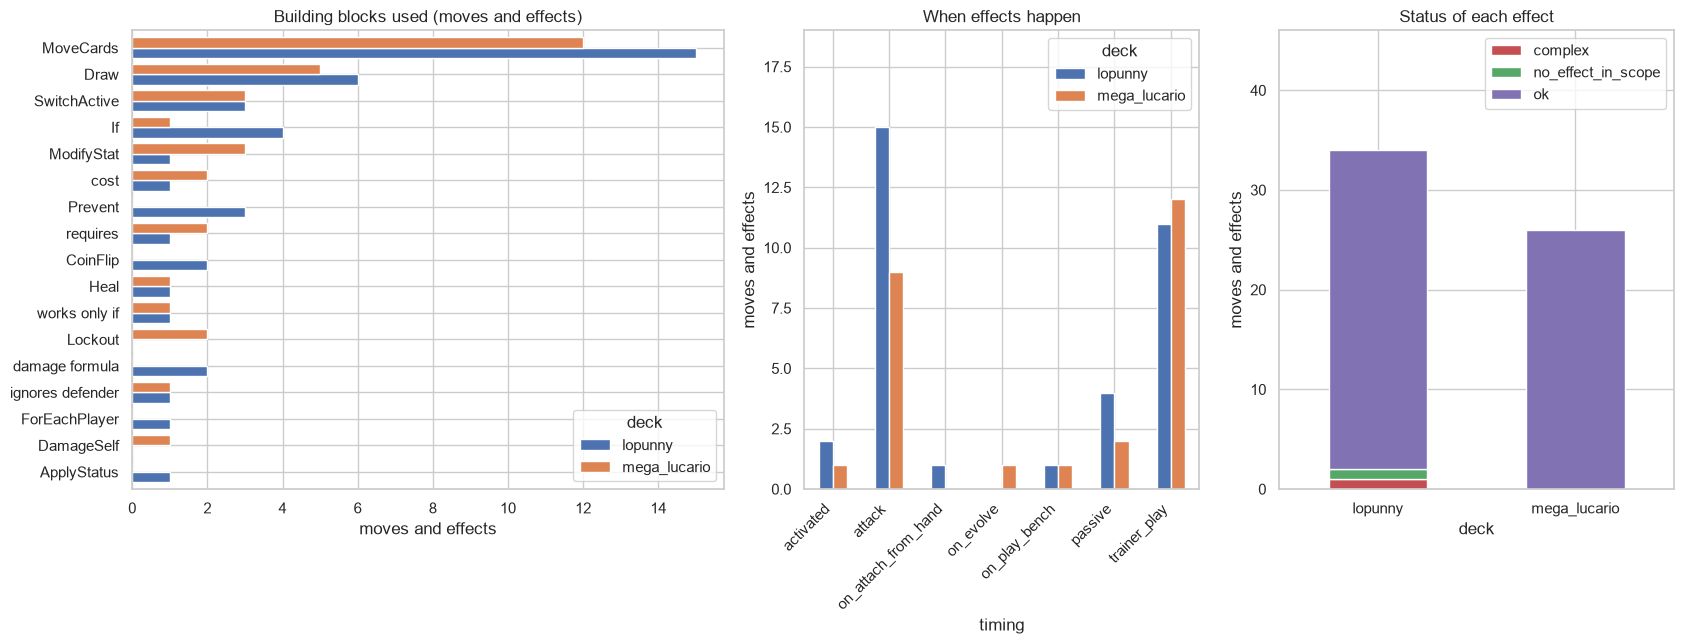

In [41]:
# 8b. The same information as charts
fig, axes = plt.subplots(1, 3, figsize=(17, 6.6), gridspec_kw={"width_ratios": [1.5, 1, 1]})
step_counts.loc[step_counts.sum(axis=1).sort_values().index].plot.barh(ax=axes[0], color=["#4c72b0", "#dd8452"], width=0.8)
axes[0].set_title("Building blocks used (moves and effects)"); axes[0].set_xlabel("moves and effects"); axes[0].set_ylabel(""); axes[0].legend(title="deck", loc="lower right")

timing = result.groupby(["deck", "timing"]).size().unstack(fill_value=0)
timing.T.plot.bar(ax=axes[1], color=["#4c72b0", "#dd8452"], rot=45); axes[1].set_title("When effects happen"); axes[1].set_ylabel("moves and effects"); axes[1].set_ylim(0, 19); axes[1].legend(title="deck", loc="upper right")
for lab in axes[1].get_xticklabels(): lab.set_ha("right")

st = result.groupby(["deck", "status"]).size().unstack(fill_value=0)
st.plot.bar(ax=axes[2], stacked=True, rot=0, color=["#c44e52", "#55a868", "#8172b3"][:len(st.columns)]); axes[2].set_title("Status of each effect"); axes[2].set_ylabel("moves and effects"); axes[2].set_ylim(0, 46); axes[2].legend(loc="upper right")
plt.tight_layout(); plt.show()

## 9. Tying it to the tests

Everything above is analysis. The **tests** are what keep the hand-written side of it honest as the project changes. The cell below runs the project's test suite from inside this notebook and groups the results by test, with a one-line statement of what each one guards.

**Reading the table.** A test with several cases (for example one case per effect) is parameterised, so `cases` is how many things it checked. `skipped` marks deliberate exceptions, and each has its reason in the test file:
- Gale Thrust repeats the printed 60 in its damage formula (checked by its own test).
- Air Balloon writes its amount as two `{C}` symbols.

**Why this belongs in an EDA.** The claims in sections 4, 7 and 8 rest on the gold set. If someone edits the effect data and breaks it, the matching test fails and this table shows `failed`, so the EDA cannot quietly drift away from the data.

The runner needs the project kernel, because it starts pytest with this kernel's Python from the project folder.

In [44]:
import os
# run pytest with colour switched off (a notebook kernel can force colour, which hides the test names from the parser)
env = {**os.environ, "NO_COLOR": "1", "PY_COLORS": "0"}
env.pop("FORCE_COLOR", None)
proc = subprocess.run([sys.executable, "-m", "pytest", "tests", "-v", "--tb=no", "-p", "no:cacheprovider"],
                      cwd=ROOT, capture_output=True, text=True, env=env)
out = re.sub(r"\x1b\[[0-9;]*m", "", proc.stdout)                  # strip colour codes if any still appear
rows = []
for line in out.splitlines():
    m = re.match(r"(tests/[\w./]+)::(\w+)(?:\[.*?\])?\s+(PASSED|FAILED|SKIPPED|ERROR)", line)
    if m:
        rows.append({"file": Path(m.group(1)).name, "test": m.group(2), "outcome": m.group(3).lower()})
if not rows:
    raise RuntimeError("no test lines found in pytest's output.\n--- stdout (tail) ---\n" + out[-800:] + "\n--- stderr (tail) ---\n" + proc.stderr[-800:])
GUARDS = {
    "test_every_deck_expands_to_60_instances": "each deck becomes exactly 60 card instances",
    "test_tags_are_unique_and_follow_the_pattern": "card tags are unique and numbered 1, 2, 3... per type",
    "test_instance_counts_match_copies": "copies of each card match the deck table",
    "test_family_in_the_tag_matches_the_card": "the type inside a tag matches the card",
    "test_two_dunsparce_versions_stay_separate": "two different cards with one name stay separate",
    "test_expansion_is_deterministic": "same deck, same tags, every time",
    "test_unknown_deck_raises": "an unknown deck name is an error",
    "test_one_effect_per_in_scope_move": "every move in the two decks has exactly one hand-written effect",
    "test_every_effect_builds": "every effect uses only the allowed vocabulary",
    "test_only_known_effects_are_not_ok": "only Lucian and Psyduck's Damp may be non-ok",
    "test_attack_timing_matches_the_move_kind": "attacks are attacks, abilities are not",
    "test_plain_damage_attacks_are_exactly_the_moves_without_text": "plain-damage attacks = moves with no effect text",
    "test_ability_usage_tags_match_the_card_text": "once-per-turn, per-name and first-turn tags agree with the text",
    "test_filters_only_use_values_that_exist_in_the_cards_table": "card filters use real kinds, types and families",
    "test_schema_rejects_mistakes": "unknown blocks, zones, conditions and statuses are rejected",
    "test_numbers_in_the_text_match_the_numbers_in_the_data": "numbers in each card text match the data",
    "test_key_words_in_the_text_match_the_parameters": "reveal, shuffle, up to, you may, next turn, flip match the data",
    "test_gale_thrust_base_matches_the_printed_damage": "the 60 in Gale Thrust's formula is the printed damage",
    "test_damp_has_nothing_to_switch_off_in_these_decks": "no ability in the decks Knocks its own Pokémon Out",
    "test_lucian_is_written_with_a_coin_flip_for_each_player": "Lucian is written as a coin flip per player",
}
t = pd.DataFrame(rows)
summary = (t.assign(n=1).pivot_table(index=["file", "test"], columns="outcome", values="n", aggfunc="sum", fill_value=0)
           .reindex(columns=["passed", "failed", "skipped", "error"], fill_value=0))
summary["cases"] = summary.sum(axis=1)
summary["guards"] = [GUARDS.get(i[1], "") for i in summary.index]
print(out.strip().splitlines()[-1])
summary.reset_index().to_string(index=False, max_colwidth=70)

======================== 115 passed, 2 skipped in 0.37s ========================


"                 file                                                         test  passed  failed  skipped  error  cases                                                          guards\n        test_decks.py                      test_every_deck_expands_to_60_instances       2       0        0      0      2                     each deck becomes exactly 60 card instances\n        test_decks.py                              test_expansion_is_deterministic       1       0        0      0      1                                same deck, same tags, every time\n        test_decks.py                      test_family_in_the_tag_matches_the_card       2       0        0      0      2                          the type inside a tag matches the card\n        test_decks.py                            test_instance_counts_match_copies       2       0        0      0      2                        copies of each card match the deck table\n        test_decks.py                  test_tags_are_unique_and_

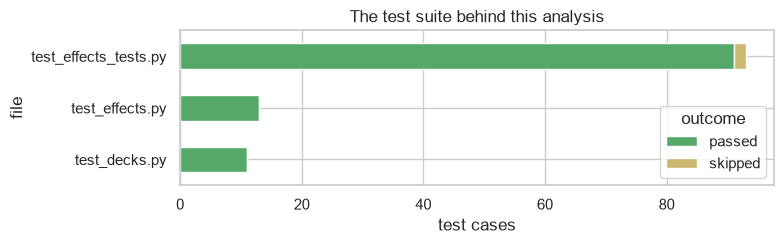

In [45]:
# the same result as one chart: how many cases each test file checks, and the outcome
by_file = t.groupby(["file", "outcome"]).size().unstack(fill_value=0)
ax = by_file.plot.barh(stacked=True, figsize=(8, 2.6), color={"passed": "#55a868", "skipped": "#ccb974", "failed": "#c44e52", "error": "#c44e52"})
ax.set_xlabel("test cases"); ax.set_title("The test suite behind this analysis"); plt.tight_layout(); plt.show()

## 10. What this establishes, and what it does not

| Claim | Evidence in this notebook | Strength |
|---|---|---|
| Exact templates cannot tag the pool | most templates appear once; hundreds are needed for 80% of sentences (section 2) | strong |
| A few regex patterns label most effects cheaply | 17 patterns, about 82% coverage, steep curve then plateau (section 3) | strong |
| The patterns agree with the hand-written gold set | 45 of 45 effects match, but tuned on them, and the first draft was worse (section 4) | weak: optimistic |
| The unlabelled tail is worded like the head | median similarity 0.55 (section 5) | moderate |
| A classifier can reproduce the labels from wording | macro F1 about 0.96 in cross-validation (section 6) | feasibility only: the labels come from the regex |
| The vocabulary has real gaps | spot-check: 6 of 22 outside effects (section 7) | moderate: small sample |
| The two decks are covered and consistent | 54 effects tagged, 52 `ok`, and the whole test suite passing (sections 8 and 9) | strong for consistency, not yet for meaning |

**What is not yet shown.**
- *Meaning.* The tests check that the effect data agrees with the card text in numbers, key words and structure. They cannot check that a source, side or condition is right. A person still needs to review the 45 effects with text.
- *The tail's accuracy.* The classifier has never been scored against hand labels outside the two decks. The plan is to hand-label about 60 random outside effects plus about 40 of the unlabelled ones, then report precision and recall on that holdout.
- *Rules.* Four rules rows (Mega turn ending, Mega Prize count, Resistance amount, ending a turn without attacking) still wait for a player's confirmation.

**What this justifies for the method.** Write rules for the common verbs, check them against a hand-written gold set, use a classifier only for the tail and only after it is scored on hand labels, mark anything else `unknown`, and extend the vocabulary deliberately. The tests keep the hand-written part honest while that happens.